# Quiz 3

Comparing two classifiers from their predicted probabilities (quiz3-data.csv, columns Class, P_M1, P_M2): ROC points and thresholds, F1 score of model 2 at a 0.5 cut-off, AUC of both models and the ROC plot.

In [1]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder
from sklearn.naive_bayes import CategoricalNB, GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc

data = pd.read_csv("./quiz3-data.csv")
print(data)
ytest = data.loc[:,'Class']
predprobM1 = data.loc[:,'P_M1']
predprobM2 = data.loc[:,'P_M2']
fpr1, tpr1, thresholds = roc_curve(ytest, predprobM1)
fpr2, tpr2, thresholds = roc_curve(ytest, predprobM2)

   Class  P_M1  P_M2
0      1  0.73  0.61
1      1  0.69  0.03
2      0  0.44  0.68
3      0  0.55  0.31
4      1  0.67  0.45
5      1  0.47  0.09
6      0  0.08  0.38
7      0  0.15  0.05
8      1  0.45  0.01
9      0  0.35  0.04


In [2]:
for i in range(len(tpr1)):
    print("tpr1 is ", tpr1[i], "and threshold is ", thresholds[i])
 

tpr1 is  0.0 and threshold is  inf
tpr1 is  0.2 and threshold is  0.68
tpr1 is  0.6 and threshold is  0.45
tpr1 is  0.6 and threshold is  0.31
tpr1 is  1.0 and threshold is  0.09
tpr1 is  1.0 and threshold is  0.04


In [3]:
print("F1 Score: ", round(f1_score(ytest, round(predprobM2), pos_label=1),4))

F1 Score:  0.2857


In [4]:
print("AUC_M1: ", auc(fpr1, tpr1))
print("AUC_M2: ", auc(fpr2, tpr2))

AUC_M1:  0.92
AUC_M2:  0.4


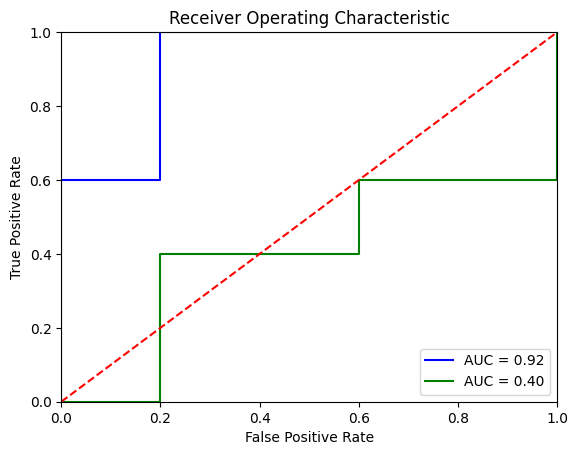

In [5]:
import matplotlib.pyplot as plt
plt.title('Receiver Operating Characteristic')
plt.plot(fpr1, tpr1, 'b', label = 'AUC = %0.2f' % auc(fpr1, tpr1))
plt.plot(fpr2, tpr2, 'g', label = 'AUC = %0.2f' % auc(fpr2, tpr2))
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'r--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()